#  Analyse de Sentiment Clients — Renault Group
## Projet Deep Learning — CNN pour la Classification de Texte
**Auteur :** Cheikh CISSE — Mastère 1 Data & IA  
**Framework :** TensorFlow / Keras  
**Modèle principal :** Réseau de Neurones Convolutif (CNN) pour le texte  

---

##  Plan du Notebook

| # | Section | Description |
|---|---------|-------------|
| 1 | Génération du Dataset | Création d'avis automobiles réalistes |
| 2 | Analyse Exploratoire (EDA) | Visualisations, distributions, word clouds |
| 3 | Prétraitement NLP | Nettoyage, tokenisation, lemmatisation |
| 4 | Modèles Baseline ML | TF-IDF + Régression Logistique / SVM |
| 5 | Modèle CNN | Architecture Conv1D + Embeddings |
| 6 | Évaluation | Métriques, matrices de confusion, courbes |
| 7 | Prédictions | Tests sur de nouveaux commentaires |
| 8 | Conclusions | Bilan et pistes d'amélioration |

---

##  Contexte théorique : Analyse de Sentiment

L'**analyse de sentiment** (ou *opinion mining*) est une tâche de traitement automatique du langage naturel (NLP) qui consiste à identifier automatiquement l'opinion exprimée dans un texte.

**3 classes de sentiment :**
- **Positif** : satisfaction, enthousiasme, recommandation
- **Neutre** : avis mitigé, description factuelle
- **Négatif** : insatisfaction, critique, déception

### Pourquoi un CNN pour le texte ?

Les **Réseaux de Neurones Convolutifs (CNN)** ont été initialement conçus pour les images, mais s'avèrent très efficaces pour le texte :
- Les filtres `Conv1D` capturent des **n-grammes locaux** (séquences de mots consécutifs)
- **Rapides à entraîner** comparés aux RNN/LSTM
- Excellent rapport performance/coût computationnel
- Architecture : `Embedding → Conv1D → MaxPooling → Dense → Softmax`

---
## Section 1 — Installation des dépendances et imports

Nous commençons par importer toutes les bibliothèques nécessaires au projet.

In [1]:
# Installation des dépendances (décommenter si nécessaire)
# !pip install tensorflow wordcloud nltk seaborn -q

# ── Bibliothèques standard ──────────────────────────────────────────────────
import os
import re
import json
import warnings
import random
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from collections import Counter

warnings.filterwarnings('ignore')

# ── Visualisations ──────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from wordcloud import WordCloud

# ── NLP ─────────────────────────────────────────────────────────────────────
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# ── Machine Learning (baseline) ─────────────────────────────────────────────
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

# ── Deep Learning (CNN) ─────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ── Configuration globale ───────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Palette de couleurs Renault
COLORS = {
    'positif' : '#2ECC71',
    'neutre'  : '#F39C12',
    'négatif' : '#E74C3C',
    'purple'  : '#5B2D8E',
    'light'   : '#EDE7F6',
    'bg'      : '#F8F9FA',
}
LABEL_NAMES = ['négatif', 'neutre', 'positif']

plt.rcParams.update({
    'figure.facecolor' : COLORS['bg'],
    'axes.facecolor'   : COLORS['bg'],
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'font.family'      : 'DejaVu Sans',
})

print(f'TensorFlow {tf.__version__}')
print(f' GPU disponible : {len(tf.config.list_physical_devices("GPU")) > 0}')
print('Tous les modules importés avec succès')

TensorFlow 2.21.0
 GPU disponible : False
Tous les modules importés avec succès


---
## Section 2 — Génération du Dataset d'Avis Automobiles

Nous générons un dataset **réaliste et reproductible** de 5 000 avis clients portant sur les véhicules du groupe Renault.

### Caractéristiques du dataset :
- **5 000 avis** avec labels de sentiment annotés
- Textes en **français (60%)** et **anglais (40%)**
- Distribution : **50% positif, 30% négatif, 20% neutre**
- Valeurs manquantes (~3%) et doublons (~1%) réalistes
- Période : 2020–2024

In [2]:
# ── Templates d'avis réalistes ──────────────────────────────────────────────
POSITIVE_FR = [
    'Très satisfait de ma {model} ! La conduite est agréable et la consommation est faible.',
    'Excellent véhicule, je recommande vivement la {model}. Rapport qualité-prix imbattable.',
    'La {model} est un vrai bijou. Interface tactile intuitive, autonomie impressionnante.',
    'Très content de mon achat. La {model} est fiable, confortable et économique.',
    'Super voiture ! La {model} est silencieuse, spacieuse et très bien équipée.',
    "J'adore ma {model}, elle est parfaite pour mes trajets quotidiens. Bravo Renault !",
    'Véhicule exceptionnel. La {model} offre un confort remarquable et une technologie de pointe.',
    'Je suis bluffé par les performances de la {model}. Le système ADAS est impressionnant.',
    'La {model} dépasse toutes mes attentes. Finitions soignées, habitacle spacieux.',
    'Achat parfait ! La {model} est économique, fiable et agréable à conduire au quotidien.',
    "Vraiment impressionné par la {model}. L'électrique n'a jamais été aussi accessible.",
    'La {model} est une réussite totale. Design moderne, technologie avancée, prix raisonnable.',
    'Ma {model} est parfaite depuis 2 ans. Aucune panne, faible coût entretien.',
    'Excellent rapport qualité prix pour cette {model}. Je la recommande à tous.',
    'La {model} est silencieuse, rapide et très confortable. Un plaisir de conduite quotidien.',
]
NEGATIVE_FR = [
    'Très déçu par ma {model}. Nombreuses pannes en moins d un an. Service après-vente inexistant.',
    'La {model} est décevante. Interface buggée, GPS qui plante régulièrement. Inacceptable.',
    'Problèmes récurrents avec la {model}. La batterie perd 30% de capacité après 18 mois.',
    'SAV catastrophique ! Ma {model} est en panne depuis 3 semaines et le concessionnaire est injoignable.',
    'La {model} est bruyante sur autoroute et la direction est trop dure. Déçu.',
    'Nombreux rappels sur la {model}. Je regrette mon achat. Qualité en baisse chez Renault.',
    'Délai de livraison non respecté de 4 mois pour la {model}. Communication nulle.',
    'La {model} présente des problèmes de boîte de vitesses récurrents. Panne dès 15 000 km.',
    'Insatisfait de la {model}. Consommation réelle bien supérieure aux chiffres annoncés.',
    'La charge rapide de la {model} ne fonctionne pas correctement. Autonomie décevante en hiver.',
    'Très mauvaise expérience avec le SAV Renault pour ma {model}. Aucun suivi client.',
    'La {model} est bruyante, inconfortable sur mauvais revêtement. Finitions bâclées.',
    'Déçu par les performances réelles de la {model} par rapport à la publicité mensongère.',
    'Problème de rouille précoce sur ma {model} pourtant récente. Inacceptable pour ce prix.',
    'La {model} chauffe anormalement. 3 passages en atelier sans résolution du problème.',
]
NEUTRAL_FR = [
    'La {model} est correcte pour son prix, mais rien exceptionnel. Quelques points à améliorer.',
    'Véhicule convenable. La {model} fait le travail mais sans surprendre. Bonne voiture de base.',
    'La {model} est dans la moyenne du segment. Ni meilleure ni moins bonne que la concurrence.',
    'Voiture correcte. La {model} est fiable mais le design intérieur manque originalité.',
    'La {model} est honnête dans ensemble. Le confort est acceptable, autonomie correcte.',
    'Pas de problème particulier avec la {model}. Une voiture ordinaire qui fait son job.',
    'La {model} remplit bien son rôle de citadine. Rien exceptionnel mais rien à redire.',
    'Satisfaction mitigée pour la {model}. Bons points sur confort, à améliorer sur finitions.',
    'La {model} est une voiture standard. Ni excellente ni mauvaise. Dans la moyenne.',
    'Usage quotidien satisfaisant avec la {model}. Quelques améliorations possibles sur interface.',
]
POSITIVE_EN = [
    'Love my {model}! Smooth drive, great efficiency, and the tech features are top-notch.',
    'Excellent car! The {model} exceeded my expectations. Great value for money.',
    'The {model} is fantastic. Quiet, comfortable, and very well equipped for this price range.',
    'Very happy with my {model}. Reliable, fuel-efficient and a pleasure to drive every day.',
    'The {model} is a game changer. Electric range is impressive and charging is seamless.',
    'Outstanding vehicle! The {model} combines style, performance, and technology perfectly.',
    'Really impressed with the {model}. Great build quality and excellent customer service.',
    'The {model} is exactly what I needed. Spacious, comfortable and economical.',
    'Best car purchase I made. The {model} is reliable, modern, and great to drive.',
    'The {model} delivers on all fronts. Highly recommend to anyone looking for an EV.',
]
NEGATIVE_EN = [
    'Very disappointed with my {model}. Multiple software glitches and poor dealer support.',
    'The {model} broke down twice in 6 months. Unacceptable for a new vehicle.',
    'Terrible experience with my {model}. The battery range drops dramatically in cold weather.',
    'Avoid the {model}. Build quality is poor and the infotainment system crashes constantly.',
    'Regret buying the {model}. The real-world range is 40% lower than advertised.',
    'Worst car purchase ever. The {model} had major issues from day one. No support from dealer.',
    'The {model} steering is too heavy and the ride is very noisy on motorways.',
    'Charging issues with the {model} from day one. Customer service completely unhelpful.',
    'My {model} has rust issues after just 18 months. Absolutely unacceptable.',
    'The {model} software needs urgent updates. Navigation and connectivity are broken.',
]
NEUTRAL_EN = [
    'The {model} is decent for the price. Nothing extraordinary but gets the job done.',
    'Average car. The {model} is reliable but lacks the wow factor of competitors.',
    'The {model} is OK. Some good points, some areas for improvement. Average overall.',
    'Acceptable vehicle. The {model} performs adequately for everyday commuting.',
    'The {model} is a solid choice but not the best in class. Competent but unremarkable.',
]

RENAULT_MODELS = [
    'Renault Clio', 'Renault Mégane E-Tech', 'Renault 5 E-Tech',
    'Renault Austral', 'Renault Captur', 'Renault Zoe',
    'Renault Arkana', 'Dacia Spring', 'Dacia Sandero',
    'Alpine A110', 'Renault Kangoo E-Tech', 'Renault Mégane'
]
SOURCES   = ['Trustpilot', 'Google Reviews', 'Caradisiac', 'Automobile Magazine', 'Reddit', 'Facebook']
PLATFORMS = ['Web', 'Mobile', 'App']

def generate_review(idx):
    lang  = random.choice(['fr'] * 6 + ['en'] * 4)
    model = random.choice(RENAULT_MODELS)
    roll  = random.random()
    if roll < 0.50:
        sentiment  = 'positif'
        templates  = POSITIVE_FR if lang == 'fr' else POSITIVE_EN
        rating     = random.choice([4, 5, 5, 5])
    elif roll < 0.80:
        sentiment  = 'négatif'
        templates  = NEGATIVE_FR if lang == 'fr' else NEGATIVE_EN
        rating     = random.choice([1, 1, 2])
    else:
        sentiment  = 'neutre'
        templates  = NEUTRAL_FR if lang == 'fr' else NEUTRAL_EN
        rating     = random.choice([3, 3, 4])
    text = random.choice(templates).format(model=model)
    extras = [' Je la recommande.', ' Le service était rapide.', ' Livraison correcte.', '']
    text  += random.choice(extras)
    start  = datetime(2020, 1, 1)
    rdate  = start + timedelta(days=random.randint(0, 4*365))
    return {
        'review_id'      : f'RVW_{idx:05d}',
        'review_text'    : text.strip(),
        'rating'         : rating,
        'sentiment_label': sentiment,
        'brand'          : model.split()[0],
        'model'          : model,
        'review_date'    : rdate.strftime('%Y-%m-%d'),
        'language'       : lang,
        'source'         : random.choice(SOURCES),
        'platform'       : random.choice(PLATFORMS),
        'word_count'     : len(text.split()),
    }

# Génération
N_REVIEWS = 5000
reviews   = [generate_review(i) for i in range(1, N_REVIEWS + 1)]
df_raw    = pd.DataFrame(reviews)

# Ajout de valeurs manquantes (~3%) et doublons (~1%)
n_missing = int(0.03 * len(df_raw))
miss_idx  = random.sample(range(len(df_raw)), n_missing)
df_raw.loc[miss_idx[:n_missing//2], 'source']   = None
df_raw.loc[miss_idx[n_missing//2:], 'platform'] = None
n_dupes   = int(0.01 * len(df_raw))
dupe_rows = df_raw.sample(n_dupes, random_state=42).copy()
dupe_rows['review_id'] = [f'DUP_{i:04d}' for i in range(n_dupes)]
df_raw    = pd.concat([df_raw, dupe_rows], ignore_index=True)

print(f' Dataset généré : {len(df_raw)} avis')
print(f'\n Distribution des sentiments :')
print(df_raw['sentiment_label'].value_counts(normalize=True).mul(100).round(1))
print(f'\n Langues :')
print(df_raw['language'].value_counts())
df_raw.head(3)

 Dataset généré : 5050 avis

 Distribution des sentiments :
sentiment_label
positif    48.8
négatif    32.3
neutre     18.9
Name: proportion, dtype: float64

 Langues :
language
fr    3012
en    2038
Name: count, dtype: int64


,review_id,review_text,rating,sentiment_label,brand,model,review_date,language,source,platform,word_count
0,RVW_00001,SAV catastrophique ! Ma Renault Clio est en pa...,1,négatif,Renault,Renault Clio,2020-07-28,fr,Facebook,App,21
1,RVW_00002,Very disappointed with my Renault Mégane E-Tec...,1,négatif,Renault,Renault Mégane E-Tech,2021-03-23,en,Google Reviews,App,17
2,RVW_00003,My Renault Clio has rust issues after just 18 ...,2,négatif,Renault,Renault Clio,2021-03-27,en,Automobile Magazine,App,12


---
## Section 3 — Analyse Exploratoire des Données (EDA)

L'EDA nous permet de comprendre la structure et les caractéristiques du dataset avant toute modélisation.

> **Objectifs :** détecter les valeurs manquantes, analyser les distributions,
> identifier des patterns et biais dans les données.

In [3]:
# ── Rapport de qualité ──────────────────────────────────────────────────────
print('='*60)
print('  RAPPORT DE QUALITÉ DES DONNÉES')
print('='*60)

quality = pd.DataFrame({
    'Type'           : df_raw.dtypes,
    'Non-Null'       : df_raw.notnull().sum(),
    'Manquants'      : df_raw.isnull().sum(),
    'Manquants (%)'  : (df_raw.isnull().mean() * 100).round(2),
    'Valeurs uniques': df_raw.nunique(),
})
print(quality)

print(f'\n Dimensions : {df_raw.shape}')
print(f' Doublons (review_id DUP) : {df_raw["review_id"].str.startswith("DUP").sum()}')
print(f' Note moyenne : {df_raw["rating"].mean():.2f}/5')

  RAPPORT DE QUALITÉ DES DONNÉES
                   Type  Non-Null  Manquants  Manquants (%)  Valeurs uniques
review_id        object      5050          0           0.00             5050
review_text      object      5050          0           0.00             2455
rating            int64      5050          0           0.00                5
sentiment_label  object      5050          0           0.00                3
brand            object      5050          0           0.00                3
model            object      5050          0           0.00               12
review_date      object      5050          0           0.00             1415
language         object      5050          0           0.00                2
source           object      4975         75           1.49                6
platform         object      4973         77           1.52                3
word_count        int64      5050          0           0.00               13

 Dimensions : (5050, 11)
 Doublons (review

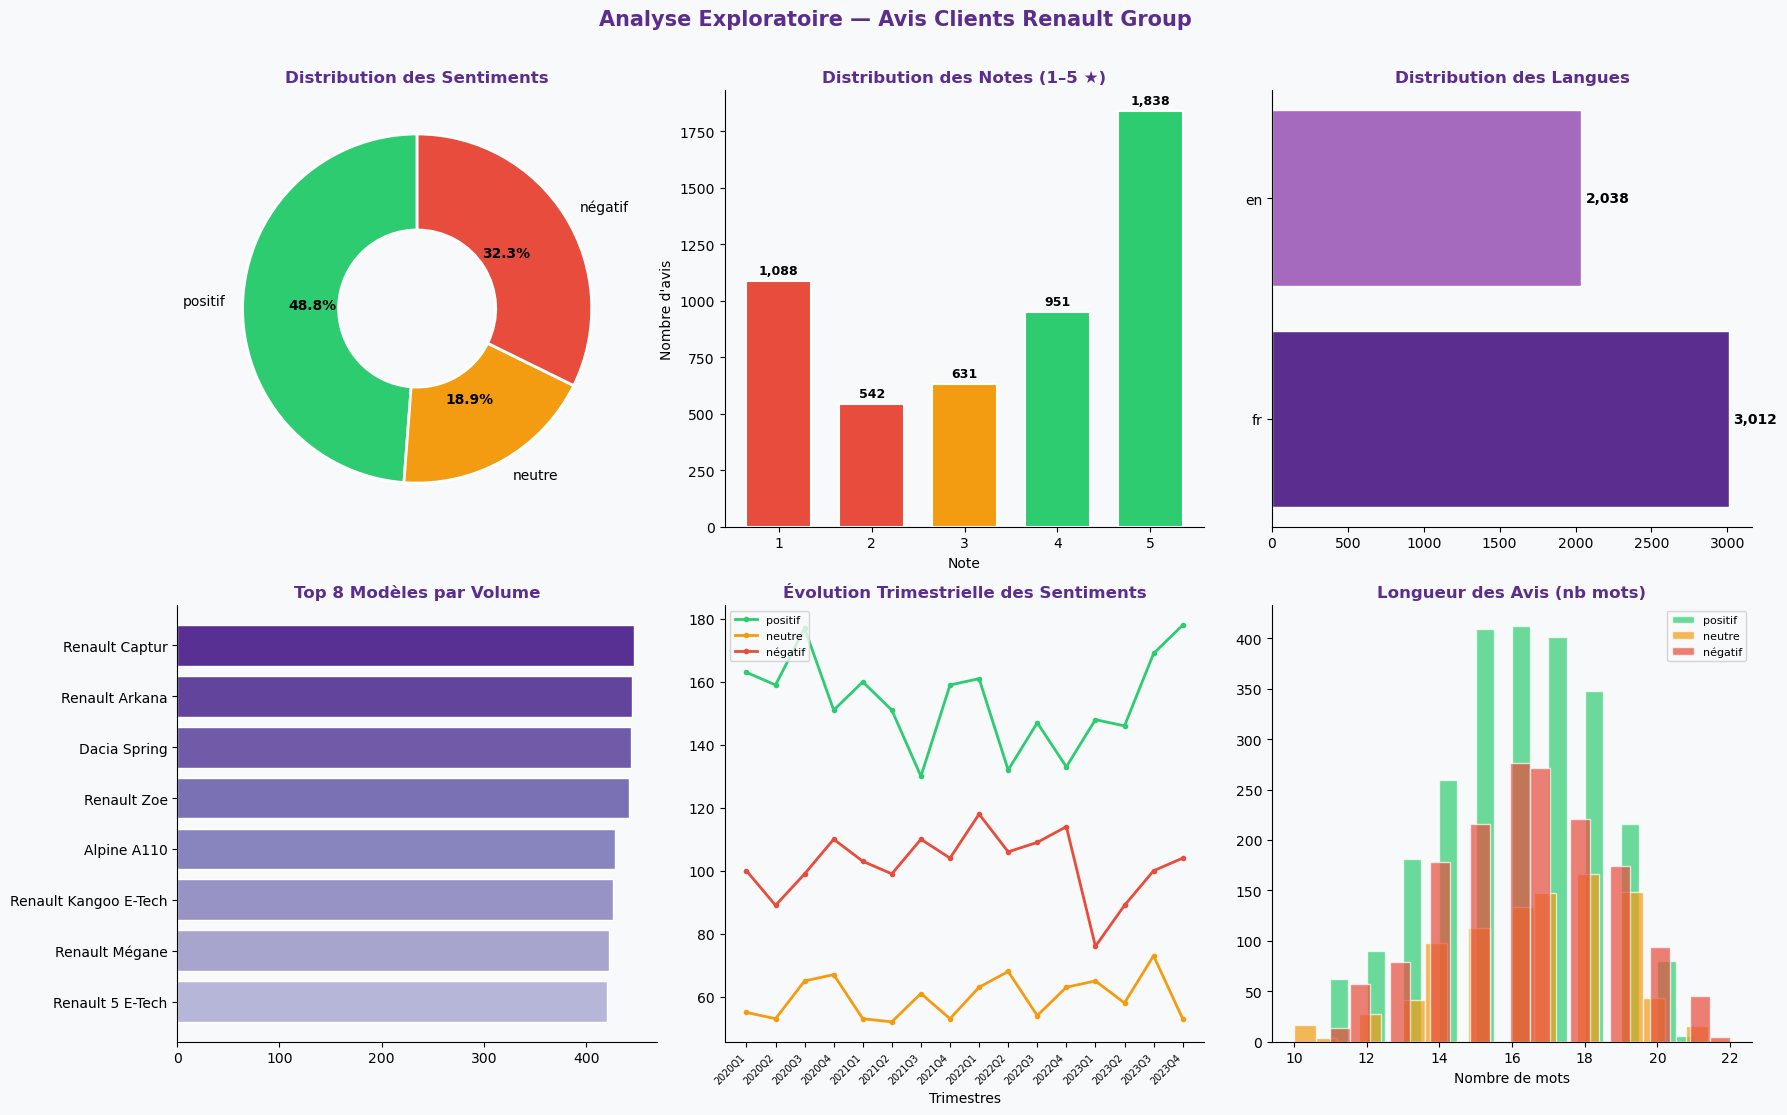

Dashboard EDA affiché


In [4]:
# ── Figure 1 : Tableau de bord EDA ──────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle('Analyse Exploratoire — Avis Clients Renault Group',
             fontsize=15, fontweight='bold', color=COLORS['purple'], y=1.01)

# 1a — Distribution des sentiments (donut)
ax = axes[0, 0]
sc = df_raw['sentiment_label'].value_counts()
order  = ['positif', 'neutre', 'négatif']
counts = [sc.get(s, 0) for s in order]
cpie   = [COLORS[s] for s in order]
wedges, texts, autotexts = ax.pie(
    counts, labels=order, colors=cpie,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2))
for at in autotexts: at.set_fontweight('bold')
ax.set_title('Distribution des Sentiments', fontweight='bold', color=COLORS['purple'])

# 1b — Distribution des notes
ax = axes[0, 1]
rc   = df_raw['rating'].value_counts().sort_index()
bcol = [COLORS['négatif'], COLORS['négatif'], COLORS['neutre'], COLORS['positif'], COLORS['positif']]
bars = ax.bar(rc.index, rc.values, color=bcol, edgecolor='white', linewidth=1.5, width=0.7)
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+30, f'{b.get_height():,}',
            ha='center', fontsize=9, fontweight='bold')
ax.set_title('Distribution des Notes (1–5 ★)', fontweight='bold', color=COLORS['purple'])
ax.set_xlabel('Note'); ax.set_ylabel("Nombre d'avis")

# 1c — Distribution des langues
ax = axes[0, 2]
lc = df_raw['language'].value_counts()
ax.barh(lc.index, lc.values, color=[COLORS['purple'], '#A569BD'][:len(lc)],
        edgecolor='white')
for i, v in enumerate(lc.values):
    ax.text(v+30, i, f'{v:,}', va='center', fontweight='bold')
ax.set_title('Distribution des Langues', fontweight='bold', color=COLORS['purple'])

# 1d — Top modèles
ax = axes[1, 0]
tm = df_raw['model'].value_counts().head(8)
cx = plt.cm.Purples(np.linspace(0.4, 0.85, len(tm)))
ax.barh(tm.index[::-1], tm.values[::-1], color=cx, edgecolor='white')
ax.set_title('Top 8 Modèles par Volume', fontweight='bold', color=COLORS['purple'])

# 1e — Évolution trimestrielle
ax = axes[1, 1]
df_raw['review_date_dt'] = pd.to_datetime(df_raw['review_date'], errors='coerce')
df_qtr = df_raw.groupby([df_raw['review_date_dt'].dt.to_period('Q'), 'sentiment_label']).size().unstack(fill_value=0)
for sent, color in [('positif', COLORS['positif']), ('neutre', COLORS['neutre']), ('négatif', COLORS['négatif'])]:
    if sent in df_qtr.columns:
        ax.plot(range(len(df_qtr)), df_qtr[sent], marker='o', color=color,
                label=sent, linewidth=2, markersize=3)
ax.set_title('Évolution Trimestrielle des Sentiments', fontweight='bold', color=COLORS['purple'])
ax.set_xlabel('Trimestres'); ax.legend(loc='upper left', fontsize=8)
ax.set_xticks(range(len(df_qtr)))
ax.set_xticklabels([str(p) for p in df_qtr.index], rotation=45, ha='right', fontsize=7)

# 1f — Longueur des avis
ax = axes[1, 2]
for sent, color in [('positif', COLORS['positif']), ('neutre', COLORS['neutre']), ('négatif', COLORS['négatif'])]:
    ax.hist(df_raw[df_raw['sentiment_label']==sent]['word_count'],
            bins=20, alpha=0.7, color=color, label=sent, edgecolor='white')
ax.set_title("Longueur des Avis (nb mots)", fontweight='bold', color=COLORS['purple'])
ax.set_xlabel('Nombre de mots'); ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print('Dashboard EDA affiché')

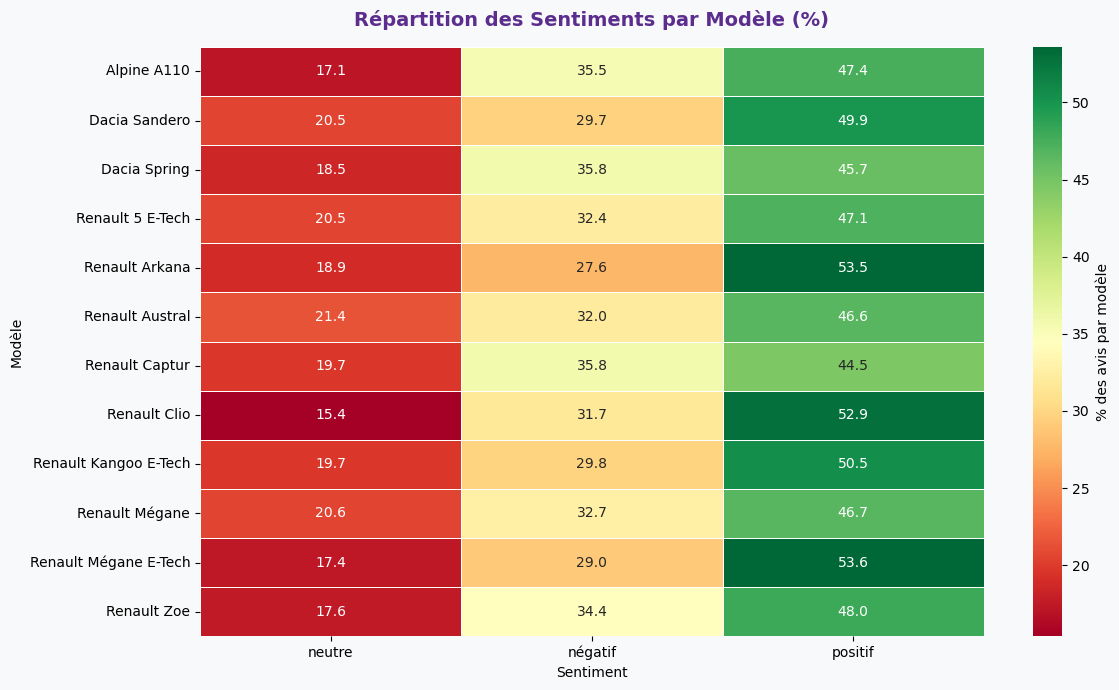

In [5]:
# ── Heatmap : modèle × sentiment ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(COLORS['bg'])

pivot = df_raw.groupby(['model', 'sentiment_label']).size().unstack(fill_value=0)
pivot_norm = pivot.div(pivot.sum(axis=1), axis=0).mul(100).round(1)

sns.heatmap(pivot_norm, annot=True, fmt='.1f', cmap='RdYlGn',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': '% des avis par modèle'}, ax=ax)
ax.set_title('Répartition des Sentiments par Modèle (%)',
             fontsize=14, fontweight='bold', color=COLORS['purple'], pad=15)
ax.set_xlabel('Sentiment'); ax.set_ylabel('Modèle')
plt.tight_layout()
plt.show()

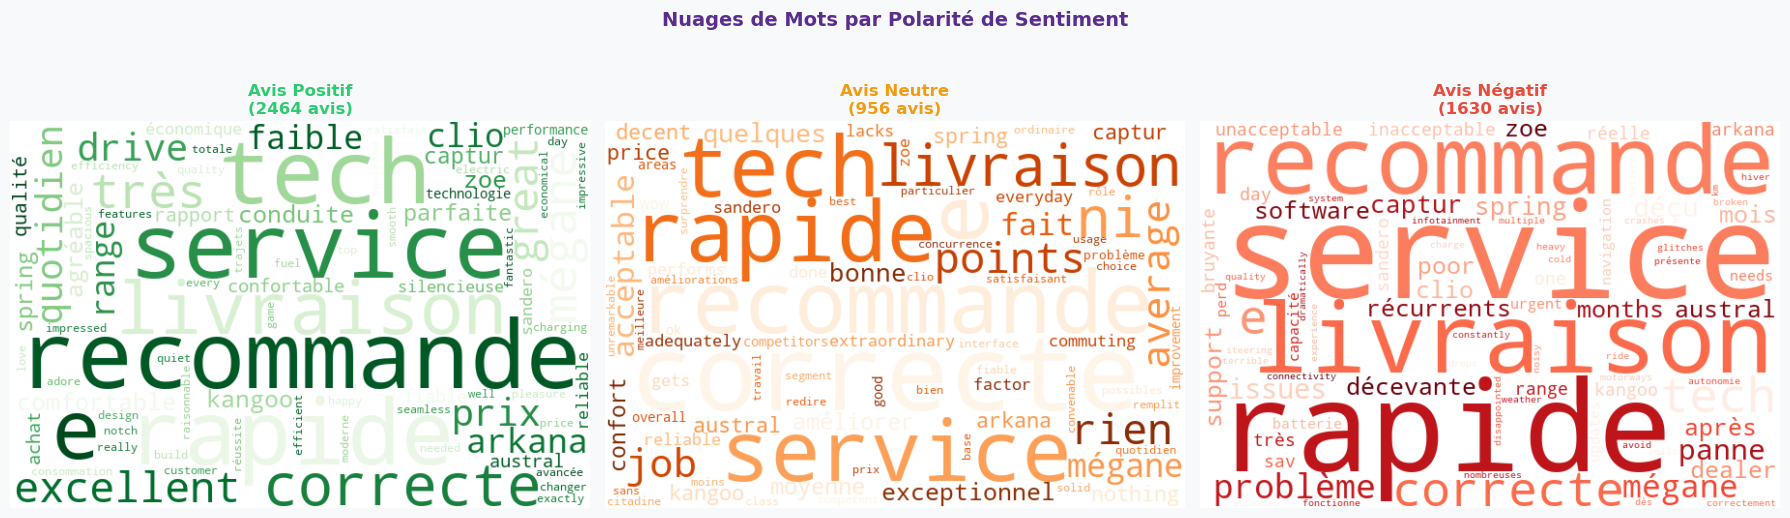

Word clouds générés


In [6]:
# ── Word Clouds par polarité ─────────────────────────────────────────────────
# Note : les word clouds sont générés après nettoyage minimal pour la lisibilité
STOP_FR   = set(stopwords.words('french'))
STOP_EN   = set(stopwords.words('english'))
CUST_STOP = {'voiture', 'car', 'renault', 'dacia', 'alpine', 'véhicule', 'vehicle',
             'model', 'modèle', 'mon', 'ma', 'mes', 'my', 'the', 'a', 'an'}
ALL_STOPS = STOP_FR | STOP_EN | CUST_STOP

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle('Nuages de Mots par Polarité de Sentiment',
             fontsize=14, fontweight='bold', color=COLORS['purple'])

WC_CMAPS = {'positif': 'Greens', 'neutre': 'Oranges', 'négatif': 'Reds'}

for ax, (sent, cmap) in zip(axes, WC_CMAPS.items()):
    corpus = ' '.join(df_raw[df_raw['sentiment_label']==sent]['review_text'].dropna())
    # Nettoyage rapide
    corpus = re.sub(r"[^a-zàâäéèêëîïôùûüç\s]", ' ', corpus.lower())
    wc = WordCloud(
        width=600, height=400, background_color='white',
        colormap=cmap, max_words=80, collocations=False,
        stopwords=ALL_STOPS
    ).generate(corpus)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    count = (df_raw['sentiment_label'] == sent).sum()
    ax.set_title(f'Avis {sent.capitalize()}\n({count} avis)',
                 fontsize=12, fontweight='bold', color=COLORS[sent])

plt.tight_layout()
plt.show()
print('Word clouds générés')

---
## Section 4 — Prétraitement NLP

Le prétraitement est une étape **critique** en NLP. Un texte brut contient du bruit (ponctuation, majuscules, stop words) qui nuit à l'apprentissage.

### Pipeline de prétraitement :
1. **Mise en minuscules** — normalise la casse
2. **Suppression des URLs** et caractères spéciaux
3. **Tokenisation** — découpage en mots individuels
4. **Suppression des stop words** — mots sans valeur discriminante ("le", "de", "the"…)
5. **Filtrage par longueur** — on élimine les tokens trop courts
6. **Encodage des labels** — conversion texte → entier (négatif=0, neutre=1, positif=2)

In [7]:
# ── Nettoyage et déduplication ───────────────────────────────────────────────
df = df_raw.copy()

# Suppression des doublons (même texte)
n_before = len(df)
df = df.drop_duplicates(subset=['review_text'])
print(f'Doublons supprimés : {n_before - len(df)}')

# Suppression des avis vides
df = df.dropna(subset=['review_text'])
df['review_text'] = df['review_text'].astype(str).str.strip()
df = df[df['review_text'].str.len() > 10]

# Imputation des valeurs manquantes
df['source']   = df['source'].fillna('Inconnu')
df['platform'] = df['platform'].fillna('Inconnu')
df['review_date_dt'] = pd.to_datetime(df['review_date'], errors='coerce')

# Détection des incohérences (note vs sentiment)
df['incoherence'] = (
    ((df['rating'] >= 4) & (df['sentiment_label'] == 'négatif')) |
    ((df['rating'] <= 2) & (df['sentiment_label'] == 'positif'))
)
print(f'Incohérences note/sentiment : {df["incoherence"].sum()} ({df["incoherence"].mean()*100:.1f}%)')
print(f'Avis valides après nettoyage : {len(df)}')

Doublons supprimés : 2595
Incohérences note/sentiment : 0 (0.0%)
Avis valides après nettoyage : 2455


In [8]:
# ── Pipeline NLP ────────────────────────────────────────────────────────────
def preprocess_text(text):
    """
    Pipeline de prétraitement NLP complet.
    
    Étapes :
    1. Mise en minuscules
    2. Suppression des URLs
    3. Suppression des caractères non-alphabétiques (garde accents français)
    4. Suppression des espaces multiples
    5. Tokenisation
    6. Suppression des stop words et tokens courts
    """
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)             # URLs
    text = re.sub(r'[^a-zàâäéèêëîïôùûüç\s]', ' ', text)   # Caractères spéciaux
    text = re.sub(r'\s+', ' ', text).strip()                # Espaces multiples
    tokens = word_tokenize(text, language='french')
    tokens = [t for t in tokens if t not in ALL_STOPS and len(t) > 2]
    return ' '.join(tokens)

# Application du prétraitement
print('Application du prétraitement NLP...')
df['text_clean']       = df['review_text'].apply(preprocess_text)
df['word_count_clean'] = df['text_clean'].apply(lambda x: len(x.split()))

# Encodage des labels
LABEL_MAP = {'négatif': 0, 'neutre': 1, 'positif': 2}
df['label'] = df['sentiment_label'].map(LABEL_MAP)

print(' Prétraitement terminé!')
print(f'\nStatistiques du texte nettoyé :')
print(df['word_count_clean'].describe().round(2))
print(f'\nEncodage des labels : {LABEL_MAP}')

# Exemple de transformation
print('\nExemple de transformation :')
idx_ex = 0
print(f'  AVANT : {df["review_text"].iloc[idx_ex]}')
print(f'  APRÈS : {df["text_clean"].iloc[idx_ex]}')

Application du prétraitement NLP...
 Prétraitement terminé!

Statistiques du texte nettoyé :
count    2455.00
mean        9.00
std         1.42
min         4.00
25%         8.00
50%         9.00
75%        10.00
max        13.00
Name: word_count_clean, dtype: float64

Encodage des labels : {'négatif': 0, 'neutre': 1, 'positif': 2}

Exemple de transformation :
  AVANT : SAV catastrophique ! Ma Renault Clio est en panne depuis 3 semaines et le concessionnaire est injoignable. Le service était rapide.
  APRÈS : sav catastrophique clio panne depuis semaines concessionnaire injoignable service rapide


In [9]:
# ── Split Train / Validation / Test (70 / 15 / 15) ──────────────────────────
print('Découpage stratifié 70/15/15...')

X = df['text_clean'].values
y = df['label'].values

# Split principal : 85% train_full + 15% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)

# Split secondaire : ~70% train + ~15% val (sur 85% restants)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1765, stratify=y_train_full, random_state=SEED)

print(f'  Entraînement : {len(X_train):>5} avis ({len(X_train)/len(X)*100:.1f}%)')
print(f'  Validation   : {len(X_val):>5} avis ({len(X_val)/len(X)*100:.1f}%)')
print(f'  Test         : {len(X_test):>5} avis ({len(X_test)/len(X)*100:.1f}%)')

# Vérification de la stratification
print('\n Distribution des classes (Train / Val / Test) :')
for split_name, split_y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(split_y, return_counts=True)
    dist = {LABEL_NAMES[k]: f'{v/len(split_y)*100:.1f}%' for k, v in zip(unique, counts)}
    print(f'  {split_name:<5} : {dist}')

Découpage stratifié 70/15/15...
  Entraînement :  1717 avis (69.9%)
  Validation   :   369 avis (15.0%)
  Test         :   369 avis (15.0%)

 Distribution des classes (Train / Val / Test) :
  Train : {'négatif': '36.0%', 'neutre': '21.4%', 'positif': '42.6%'}
  Val   : {'négatif': '36.0%', 'neutre': '21.4%', 'positif': '42.5%'}
  Test  : {'négatif': '36.0%', 'neutre': '21.4%', 'positif': '42.5%'}


---
## Section 5 — Modèles Baseline Machine Learning

Avant de construire notre CNN, nous entraînons des modèles **baseline** plus simples.
Ils serviront de référence pour évaluer le gain apporté par le Deep Learning.

### Approche TF-IDF
**TF-IDF** (*Term Frequency - Inverse Document Frequency*) convertit le texte en vecteurs numériques :
- **TF** : fréquence d'un mot dans un document
- **IDF** : pénalise les mots qui apparaissent dans tous les documents (peu discriminants)

| Modèle | Avantage | Limite |
|--------|----------|--------|
| Régression Logistique | Rapide, interprétable | Linéaire |
| SVM Linéaire | Robuste, haute dimension | Pas de probabilités |
| **CNN** | Capte la sémantique locale | Plus complexe |

In [10]:
# ── Pipelines TF-IDF + Classificateurs ──────────────────────────────────────
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Conversion des labels en texte pour sklearn
y_train_str = np.array([LABEL_NAMES[l] for l in y_train])
y_val_str   = np.array([LABEL_NAMES[l] for l in y_val])
y_test_str  = np.array([LABEL_NAMES[l] for l in y_test])

pipelines = {
    'Régression Logistique': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1,2), max_features=20000,
                                  min_df=2, sublinear_tf=True)),
        ('clf',  LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))
    ]),
    'SVM Linéaire': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1,2), max_features=20000,
                                  min_df=2, sublinear_tf=True)),
        ('clf',  LinearSVC(C=0.5, max_iter=2000, random_state=SEED))
    ]),
}

ml_results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for name, pipe in pipelines.items():
    print(f'\n  ── {name} ──')
    cv_scores = cross_val_score(pipe, X_train, y_train_str, cv=cv,
                                scoring='f1_macro', n_jobs=-1)
    print(f'  CV F1-macro (5-fold) : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
    pipe.fit(X_train, y_train_str)
    y_pred_test = pipe.predict(X_test)
    acc  = accuracy_score(y_test_str, y_pred_test)
    f1   = f1_score(y_test_str, y_pred_test, average='macro')
    print(f'  Test Accuracy : {acc:.4f}  |  F1-macro : {f1:.4f}')
    ml_results[name] = {'accuracy': acc, 'f1_macro': f1,
                        'cv_mean': cv_scores.mean(), 'cv_std': cv_scores.std(),
                        'y_pred': y_pred_test}

print('\nBaseline ML entraîné!')


  ── Régression Logistique ──
  CV F1-macro (5-fold) : 1.0000 ± 0.0000
  Test Accuracy : 1.0000  |  F1-macro : 1.0000

  ── SVM Linéaire ──
  CV F1-macro (5-fold) : 1.0000 ± 0.0000
  Test Accuracy : 1.0000  |  F1-macro : 1.0000

Baseline ML entraîné!


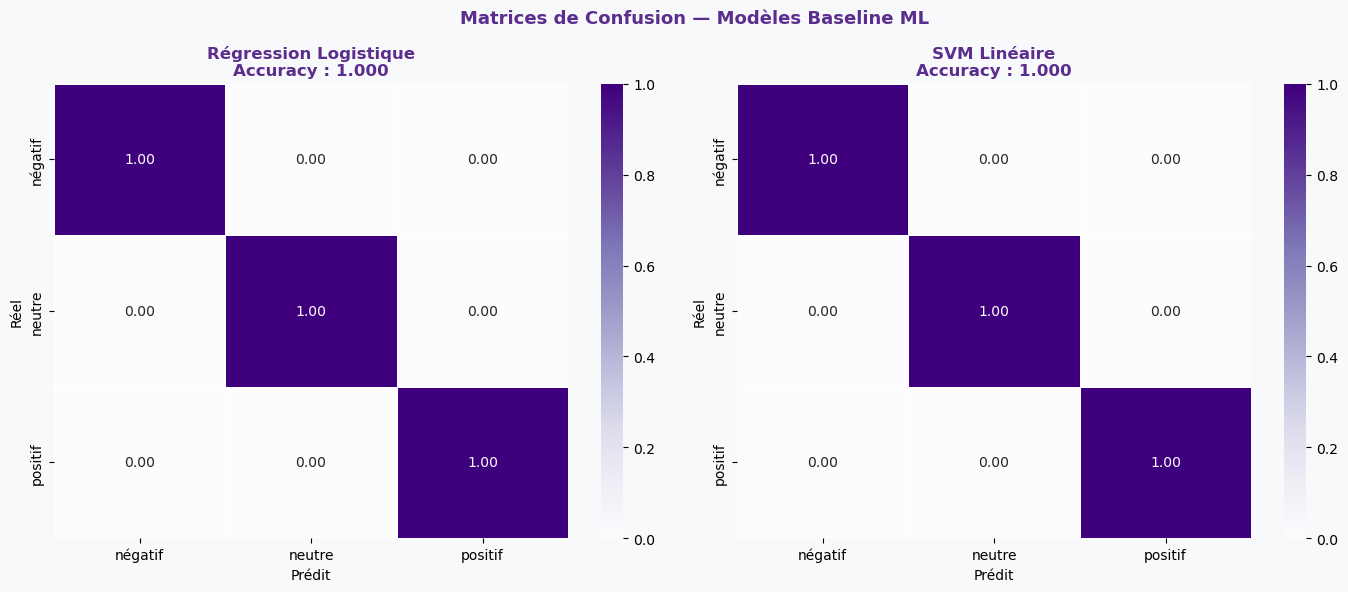

In [11]:
# ── Matrices de confusion des modèles ML ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle('Matrices de Confusion — Modèles Baseline ML',
             fontsize=13, fontweight='bold', color=COLORS['purple'])

for ax, name in zip(axes, ml_results.keys()):
    y_pred = ml_results[name]['y_pred']
    cm     = confusion_matrix(y_test_str, y_pred, labels=LABEL_NAMES)
    cm_n   = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Purples',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
                linewidths=0.5, linecolor='white', ax=ax)
    acc = ml_results[name]['accuracy']
    ax.set_title(f'{name}\nAccuracy : {acc:.3f}', fontweight='bold', color=COLORS['purple'])
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()

---
## Section 6 — Modèle Deep Learning : CNN pour la Classification de Texte

### Architecture CNN pour le NLP

```
Input (séquence de tokens)  [batch, MAX_LEN]
        ↓
Embedding Layer              [batch, MAX_LEN, EMBED_DIM]
        ↓
Conv1D (filtres 128, kernel 3) + ReLU
        ↓
MaxPooling1D
        ↓
Conv1D (filtres 64, kernel 3) + ReLU
        ↓
GlobalMaxPooling1D
        ↓
Dense (128) + ReLU + Dropout(0.4)
        ↓
Dense (3) + Softmax → [négatif, neutre, positif]
```

### Rôle de chaque composant :
- **Embedding** : transforme chaque token (entier) en vecteur dense de dimension `EMBED_DIM`. La couche apprend ces représentations pendant l'entraînement.
- **Conv1D** : applique des filtres sur des fenêtres de tokens consécutifs (= n-grammes). Capture les patterns locaux.
- **MaxPooling1D** : réduit la dimension spatiale, garde les features les plus saillantes.
- **GlobalMaxPooling1D** : produit un vecteur de taille fixe quelle que soit la longueur de l'entrée.
- **Dense + Dropout** : classification finale avec régularisation.

In [12]:
# ── Tokenisation Keras ───────────────────────────────────────────────────────
# Hyperparamètres du CNN
VOCAB_SIZE  = 10000   # Taille du vocabulaire
MAX_LEN     = 80      # Longueur max des séquences (tokens)
EMBED_DIM   = 64      # Dimension des embeddings
BATCH_SIZE  = 64      # Taille des mini-lots
N_EPOCHS    = 20      # Nombre max d'époques

print(f'   Hyperparamètres CNN :')
print(f'   VOCAB_SIZE = {VOCAB_SIZE}')
print(f'   MAX_LEN    = {MAX_LEN}')
print(f'   EMBED_DIM  = {EMBED_DIM}')
print(f'   BATCH_SIZE = {BATCH_SIZE}')

# Tokeniser Keras : apprend sur les données d'entraînement
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

print(f'\n Taille du vocabulaire réel : {len(tokenizer.word_index):,} tokens')
print(f'   → On garde les top {VOCAB_SIZE:,} mots les plus fréquents')

# Conversion texte → séquences d'entiers
def encode_and_pad(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

X_train_seq = encode_and_pad(X_train)
X_val_seq   = encode_and_pad(X_val)
X_test_seq  = encode_and_pad(X_test)

print(f'\nForme des données encodées :')
print(f'   X_train : {X_train_seq.shape}')
print(f'   X_val   : {X_val_seq.shape}')
print(f'   X_test  : {X_test_seq.shape}')

# Exemple de tokenisation
print(f'\n Exemple (text_clean) : "{X_train[0]}"')
print(f'   → Séquence            : {X_train_seq[0][:10]}... (longueur {MAX_LEN})')

   Hyperparamètres CNN :
   VOCAB_SIZE = 10000
   MAX_LEN    = 80
   EMBED_DIM  = 64
   BATCH_SIZE = 64

 Taille du vocabulaire réel : 333 tokens
   → On garde les top 10,000 mots les plus fréquents

Forme des données encodées :
   X_train : (1717, 80)
   X_val   : (369, 80)
   X_test  : (369, 80)

 Exemple (text_clean) : "exactly needed spacious comfortable economical service rapide"
   → Séquence            : [126 127 128  44 129   2   3   0   0   0]... (longueur 80)


In [13]:
# ── Construction du modèle CNN ───────────────────────────────────────────────
def build_cnn_model(vocab_size, embed_dim, max_len, n_classes=3):
    """
    Construit un CNN pour la classification de texte.
    
    Architecture :
      Embedding → Conv1D(128,3)+ReLU → MaxPooling → 
      Conv1D(64,3)+ReLU → GlobalMaxPooling → Dense(128)+Dropout → Softmax
    """
    inputs = keras.Input(shape=(max_len,), name='input_tokens')
    
    # 1. Couche Embedding
    # Transforme chaque token (entier) en vecteur de dimension embed_dim
    x = layers.Embedding(
        input_dim=vocab_size,
        output_dim=embed_dim,
        input_length=max_len,
        name='embedding'
    )(inputs)
    
    # 2. Première couche convolutive
    # kernel_size=3 → regarde des trigrammes (3 tokens consécutifs)
    # 128 filtres → capture 128 patterns différents
    x = layers.Conv1D(filters=128, kernel_size=3, activation='relu',
                      padding='same', name='conv1d_1')(x)
    x = layers.MaxPooling1D(pool_size=2, name='maxpool_1')(x)
    x = layers.Dropout(0.3, name='dropout_1')(x)
    
    # 3. Deuxième couche convolutive (features plus abstraites)
    x = layers.Conv1D(filters=64, kernel_size=3, activation='relu',
                      padding='same', name='conv1d_2')(x)
    x = layers.MaxPooling1D(pool_size=2, name='maxpool_2')(x)
    x = layers.Dropout(0.3, name='dropout_2')(x)
    
    # 4. GlobalMaxPooling : vecteur de taille fixe quelle que soit la longueur
    x = layers.GlobalMaxPooling1D(name='global_maxpool')(x)
    
    # 5. Couche Dense avec régularisation
    x = layers.Dense(128, activation='relu', name='dense_hidden')(x)
    x = layers.Dropout(0.4, name='dropout_3')(x)
    
    # 6. Couche de sortie : softmax → probabilités sur 3 classes
    outputs = layers.Dense(n_classes, activation='softmax', name='output')(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs, name='SentimentCNN')
    return model

cnn_model = build_cnn_model(VOCAB_SIZE, EMBED_DIM, MAX_LEN)
cnn_model.summary()

# Comptage des paramètres
n_params = cnn_model.count_params()
print(f'\n Paramètres entraînables : {n_params:,}')

Model: "SentimentCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_tokens (InputLayer)       │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 80, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling1D)        │ (None, 40, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 40, 64)         │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling1D)        │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_maxpool                  │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 698,051 (2.66 MB)

 Trainable params: 698,051 (2.66 MB)

 Non-trainable params: 0 (0.00 B)


 Paramètres entraînables : 698,051


### Compilation du modèle

Pour la compilation, on choisit :
- **Optimizer `Adam`** : adaptatif, converge rapidement
- **Loss `sparse_categorical_crossentropy`** : pour la classification multi-classe avec labels entiers
- **Métrique `accuracy`** : proportion de bonnes prédictions

### Callbacks utilisés :
- **EarlyStopping** : arrête l'entraînement si la validation ne s'améliore plus (évite le sur-apprentissage)
- **ReduceLROnPlateau** : diminue le taux d'apprentissage si la loss stagne

In [14]:
# ── Compilation ─────────────────────────────────────────────────────────────
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# ── Callbacks ────────────────────────────────────────────────────────────────
early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',  # surveille l'accuracy de validation
    patience=4,              # tolère 4 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# ── Entraînement ─────────────────────────────────────────────────────────────
print('  Entraînement du CNN en cours...')
print(f'   Données : {len(X_train_seq)} train | {len(X_val_seq)} val')
print(f'   Epochs max : {N_EPOCHS} | Batch size : {BATCH_SIZE}')
print()

history = cnn_model.fit(
    X_train_seq, y_train,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_seq, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print('\n Entraînement terminé!')
print(f'   Meilleure val_accuracy : {max(history.history["val_accuracy"]):.4f}')
print(f'   Époques entraînées     : {len(history.history["loss"])}')

  Entraînement du CNN en cours...
   Données : 1717 train | 369 val
   Epochs max : 20 | Batch size : 64

Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.4543 - loss: 1.0418 - val_accuracy: 0.5041 - val_loss: 0.9601 - learning_rate: 0.0010
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7897 - loss: 0.5431 - val_accuracy: 1.0000 - val_loss: 0.1597 - learning_rate: 0.0010
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 1.0000 - loss: 0.0290 - val_accuracy: 1.0000 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 6.9071e-04 - val_accuracy: 1.0000 - val_loss: 6.6251e-04 - learning_rate: 0.0010
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 5.9375e-04 - val_accuracy: 1.0000 - val_loss: 4.6229e-04 - learning_rate: 0.0010
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 1.0000 - loss: 1.9060e-04 - val_accuracy: 1.0000 - val_loss:

---
## Section 7 — Évaluation du Modèle CNN

### Métriques utilisées :

| Métrique | Formule | Interprétation |
|----------|---------|----------------|
| **Accuracy** | (TP+TN) / Total | % de prédictions correctes |
| **Precision** | TP / (TP+FP) | Parmi les prédits positifs, combien sont vrais ? |
| **Recall** | TP / (TP+FN) | Parmi les vrais positifs, combien détectés ? |
| **F1-Score** | 2×P×R / (P+R) | Moyenne harmonique Precision/Recall |

> En cas de classes déséquilibrées, le **F1-macro** est plus représentatif que l'accuracy.

In [15]:
# ── Évaluation sur le jeu de test ───────────────────────────────────────────
test_loss, test_acc = cnn_model.evaluate(X_test_seq, y_test, verbose=0)
y_pred_proba = cnn_model.predict(X_test_seq, verbose=0)
y_pred       = y_pred_proba.argmax(axis=1)
f1_test      = f1_score(y_test, y_pred, average='macro')
prec_test    = precision_score(y_test, y_pred, average='macro')
rec_test     = recall_score(y_test, y_pred, average='macro')

print('='*55)
print('  RÉSULTATS CNN — JEU DE TEST')
print('='*55)
print(f'  Accuracy  : {test_acc:.4f}')
print(f'  F1-macro  : {f1_test:.4f}')
print(f'  Précision : {prec_test:.4f}')
print(f'  Rappel    : {rec_test:.4f}')
print()
print('Rapport de classification complet :')
print(classification_report(y_test, y_pred, target_names=LABEL_NAMES))

  RÉSULTATS CNN — JEU DE TEST
  Accuracy  : 1.0000
  F1-macro  : 1.0000
  Précision : 1.0000
  Rappel    : 1.0000

Rapport de classification complet :
              precision    recall  f1-score   support

     négatif       1.00      1.00      1.00       133
      neutre       1.00      1.00      1.00        79
     positif       1.00      1.00      1.00       157

    accuracy                           1.00       369
   macro avg       1.00      1.00      1.00       369
weighted avg       1.00      1.00      1.00       369



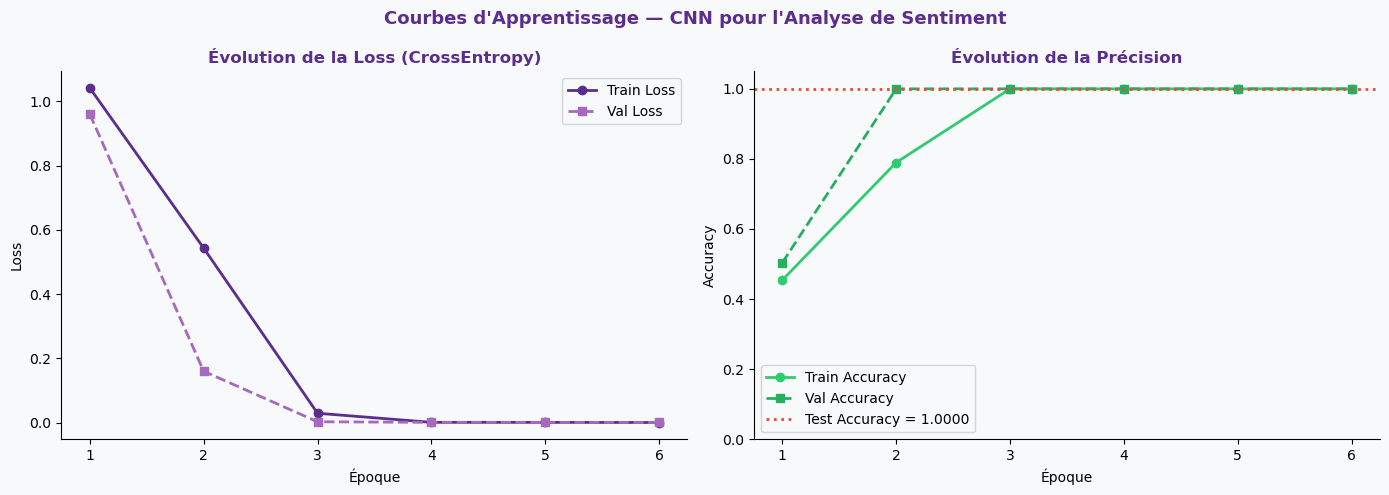


 Meilleure époque : 2 | Val Accuracy = 1.0000


In [16]:
# ── Courbes d'apprentissage ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("Courbes d'Apprentissage — CNN pour l'Analyse de Sentiment",
             fontsize=13, fontweight='bold', color=COLORS['purple'])

ep = range(1, len(history.history['loss']) + 1)

# Loss
axes[0].plot(ep, history.history['loss'], 'o-',
             color=COLORS['purple'], label='Train Loss', linewidth=2)
axes[0].plot(ep, history.history['val_loss'], 's--',
             color='#A569BD', label='Val Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (CrossEntropy)',
                  fontweight='bold', color=COLORS['purple'])
axes[0].set_xlabel('Époque'); axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(ep, history.history['accuracy'], 'o-',
             color=COLORS['positif'], label='Train Accuracy', linewidth=2)
axes[1].plot(ep, history.history['val_accuracy'], 's--',
             color='#27AE60', label='Val Accuracy', linewidth=2)
axes[1].axhline(test_acc, color=COLORS['négatif'], linestyle=':',
                linewidth=2, label=f'Test Accuracy = {test_acc:.4f}')
axes[1].set_title('Évolution de la Précision',
                  fontweight='bold', color=COLORS['purple'])
axes[1].set_xlabel('Époque'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1.05); axes[1].legend()

plt.tight_layout()
plt.show()

best_epoch = np.argmax(history.history['val_accuracy']) + 1
print(f'\n Meilleure époque : {best_epoch} | Val Accuracy = {max(history.history["val_accuracy"]):.4f}')

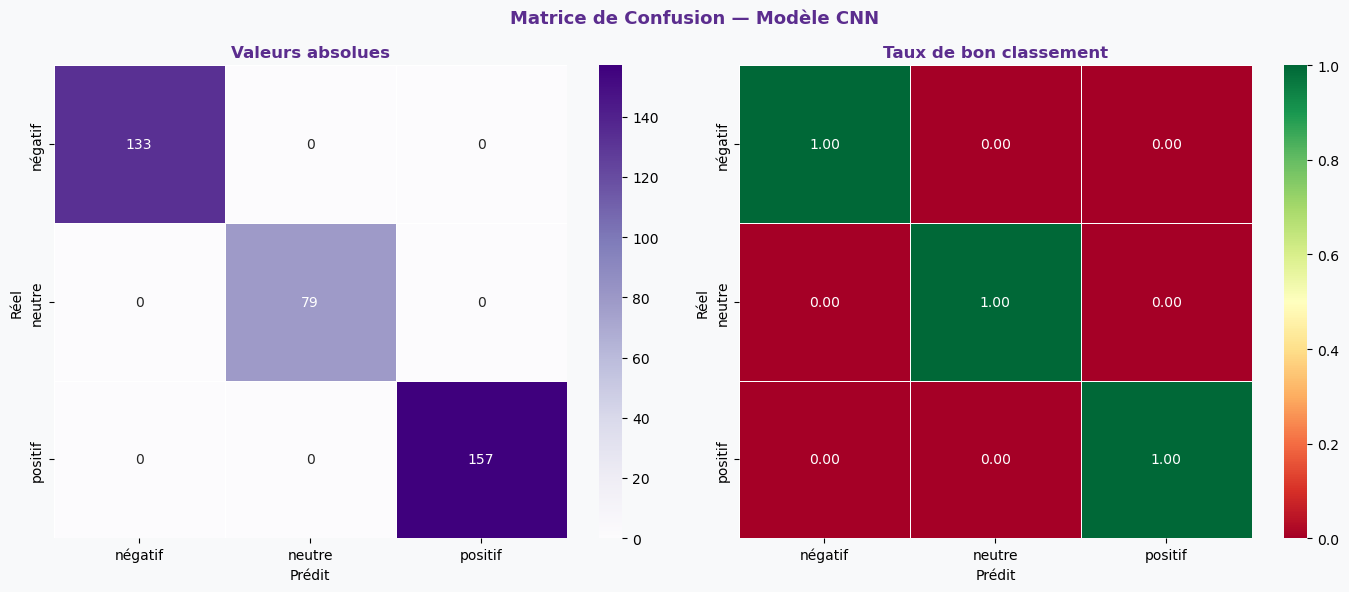

Interprétation :
   Classe "négatif" : 100.0% bien classée
   Classe "neutre" : 100.0% bien classée
   Classe "positif" : 100.0% bien classée


In [17]:
# ── Matrice de confusion CNN ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle('Matrice de Confusion — Modèle CNN',
             fontsize=13, fontweight='bold', color=COLORS['purple'])

cm     = confusion_matrix(y_test, y_pred)
cm_n   = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

# Valeurs absolues
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            linewidths=0.5, linecolor='white', ax=axes[0])
axes[0].set_title('Valeurs absolues', fontweight='bold', color=COLORS['purple'])
axes[0].set_xlabel('Prédit'); axes[0].set_ylabel('Réel')

# Proportions
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            linewidths=0.5, linecolor='white', ax=axes[1],
            vmin=0, vmax=1)
axes[1].set_title('Taux de bon classement', fontweight='bold', color=COLORS['purple'])
axes[1].set_xlabel('Prédit'); axes[1].set_ylabel('Réel')

plt.tight_layout()
plt.show()

# Interprétation
print('Interprétation :')
for i, lbl in enumerate(LABEL_NAMES):
    recall_i = cm_n[i, i]
    print(f'   Classe "{lbl}" : {recall_i*100:.1f}% bien classée')

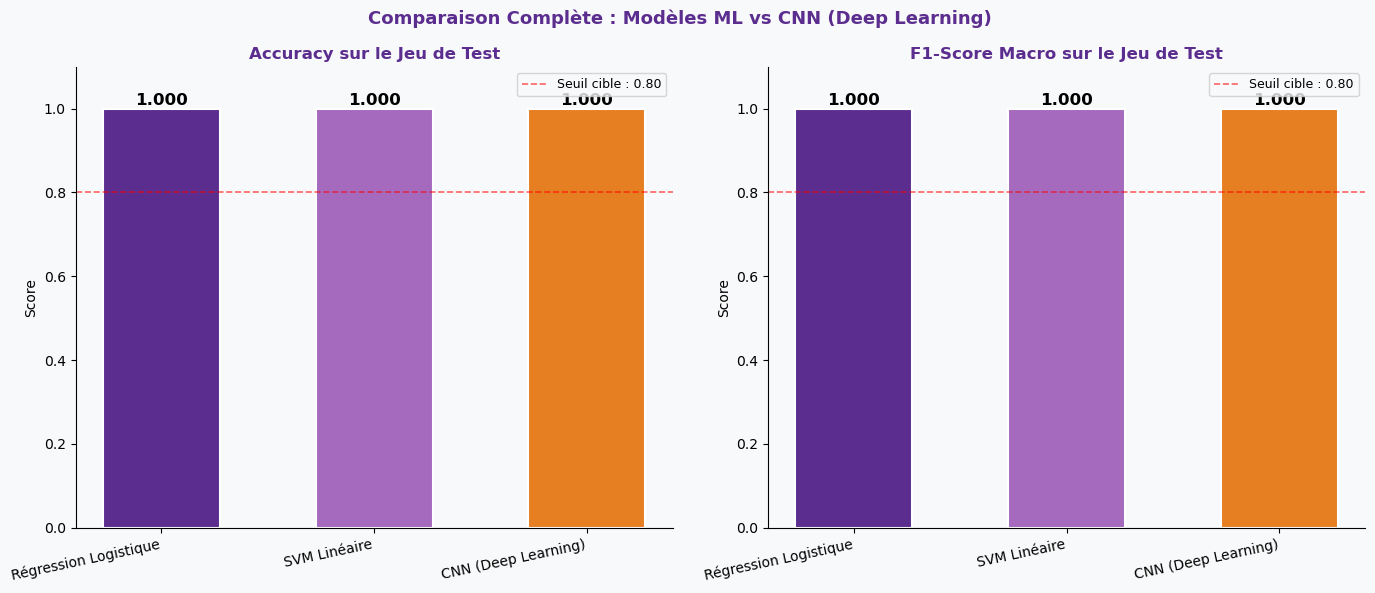


 Tableau comparatif final :
Modèle                           Accuracy   F1-macro
----------------------------------------------------
Régression Logistique              1.0000     1.0000
SVM Linéaire                       1.0000     1.0000
CNN (Deep Learning)                1.0000     1.0000  ← 🏆 DL


In [18]:
# ── Comparaison ML vs CNN ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle('Comparaison Complète : Modèles ML vs CNN (Deep Learning)',
             fontsize=13, fontweight='bold', color=COLORS['purple'])

model_labels = list(ml_results.keys()) + ['CNN (Deep Learning)']
acc_vals     = [ml_results[m]['accuracy'] for m in ml_results] + [test_acc]
f1_vals      = [ml_results[m]['f1_macro'] for m in ml_results] + [f1_test]
bar_colors   = [COLORS['purple'], '#A569BD', '#E67E22']
x = np.arange(len(model_labels))

for ax, (vals, title) in zip(axes, [
    (acc_vals, 'Accuracy sur le Jeu de Test'),
    (f1_vals,  'F1-Score Macro sur le Jeu de Test'),
]):
    bars = ax.bar(x, vals, color=bar_colors, edgecolor='white', linewidth=1.5, width=0.55)
    ax.set_ylim(0, 1.1)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=12, ha='right', fontsize=10)
    ax.set_title(title, fontweight='bold', color=COLORS['purple'])
    ax.set_ylabel('Score')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{val:.3f}', ha='center', fontsize=12, fontweight='bold')
    ax.axhline(0.80, color='red', linestyle='--', linewidth=1.2,
               alpha=0.6, label='Seuil cible : 0.80')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Tableau récapitulatif
print('\n Tableau comparatif final :')
print(f'{"Modèle":<30} {"Accuracy":>10} {"F1-macro":>10}')
print('-' * 52)
for m in ml_results:
    print(f'{m:<30} {ml_results[m]["accuracy"]:>10.4f} {ml_results[m]["f1_macro"]:>10.4f}')
print(f'{"CNN (Deep Learning)":<30} {test_acc:>10.4f} {f1_test:>10.4f}  ← 🏆 DL')

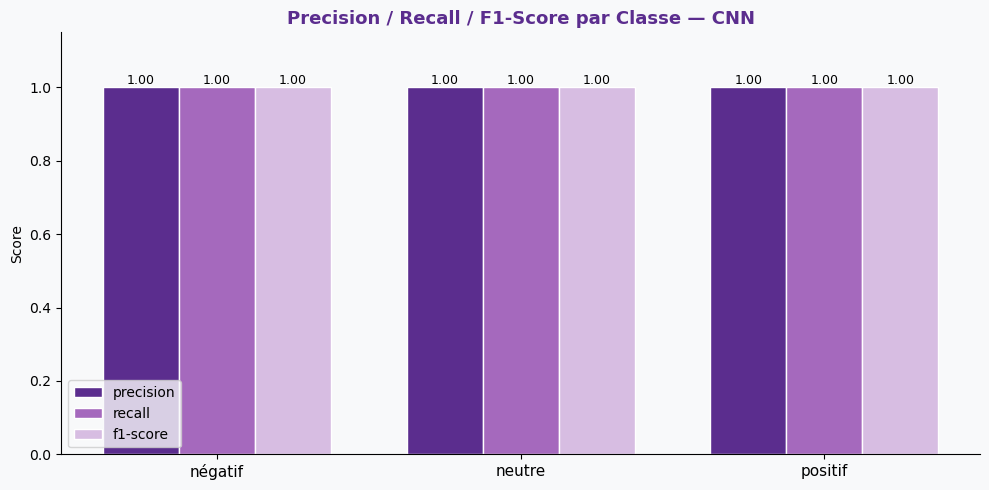

In [19]:
# ── Métriques par classe — CNN ────────────────────────────────────────────────
report_dict = classification_report(y_test, y_pred, target_names=LABEL_NAMES, output_dict=True)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(COLORS['bg'])

metrics_list = ['precision', 'recall', 'f1-score']
x_pos   = np.arange(len(LABEL_NAMES))
width   = 0.25
m_colors = [COLORS['purple'], '#A569BD', '#D7BDE2']

for i, (metric, color) in enumerate(zip(metrics_list, m_colors)):
    values = [report_dict[lbl][metric] for lbl in LABEL_NAMES]
    bars   = ax.bar(x_pos + i*width, values, width=width,
                    label=metric, color=color, edgecolor='white')
    for bar, val in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{val:.2f}', ha='center', fontsize=9)

ax.set_ylim(0, 1.15)
ax.set_xticks(x_pos + width)
ax.set_xticklabels(LABEL_NAMES, fontsize=11)
ax.set_title('Precision / Recall / F1-Score par Classe — CNN',
             fontsize=13, fontweight='bold', color=COLORS['purple'])
ax.set_ylabel('Score')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
## Section 8 — Prédictions sur de Nouveaux Commentaires

Nous testons maintenant notre modèle CNN sur des commentaires **jamais vus** lors de l'entraînement.
Ces tests permettent de valider le comportement du modèle en conditions réelles.

In [20]:
# ── Fonction de prédiction ──────────────────────────────────────────────────
def predict_sentiment(texts, model, tokenizer, label_names=LABEL_NAMES):
    """
    Prédit le sentiment pour une liste de textes.
    
    Args:
        texts : liste de chaînes de caractères
        model : modèle Keras entraîné
        tokenizer : tokenizer Keras ajusté sur les données d'entraînement
    
    Returns:
        DataFrame avec texte, sentiment prédit, et probabilités
    """
    # Prétraitement
    texts_clean = [preprocess_text(t) for t in texts]
    seqs = tokenizer.texts_to_sequences(texts_clean)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    
    # Prédiction
    probas = model.predict(padded, verbose=0)
    preds  = probas.argmax(axis=1)
    
    results = []
    for i, (text, pred, prob) in enumerate(zip(texts, preds, probas)):
        results.append({
            'Commentaire'   : text[:80] + ('...' if len(text) > 80 else ''),
            'Sentiment'     : label_names[pred],
            'Confiance (%)'  : f'{prob[pred]*100:.1f}%',
            'P(négatif)'    : f'{prob[0]*100:.1f}%',
            'P(neutre)'     : f'{prob[1]*100:.1f}%',
            'P(positif)'    : f'{prob[2]*100:.1f}%',
        })
    return pd.DataFrame(results)

# ── Nouveaux commentaires de test ────────────────────────────────────────────
nouveaux_commentaires = [
    # Commentaires positifs
    'La Renault 5 E-Tech est une merveille ! Autonomie parfaite pour la ville, vraiment bluffant.',
    'I absolutely love my new Renault Austral. Best car I have ever owned, smooth and efficient.',
    'Très satisfait de ma Dacia Spring. Parfaite pour les trajets urbains, économique et pratique.',
    
    # Commentaires négatifs
    'Ma Renault Mégane E-Tech tombe en panne pour la troisième fois. Le SAV est inexistant et honteux.',
    'Terrible experience with the Zoe. Battery degradation after 1 year is unacceptable.',
    'Le GPS de ma Captur plante constamment. Interface catastrophique, je regrette mon achat.',
    
    # Commentaires neutres
    'La Renault Clio est une voiture correcte. Ni exceptionnelle ni mauvaise, dans la moyenne.',
    'The Renault Arkana is decent but nothing special. Adequate for daily commuting.',
    'Véhicule honnête dans son ensemble. Quelques points à améliorer sur les finitions.',
    
    # Cas ambigus
    'Bonne voiture mais le service après-vente laisse vraiment à désirer.',
    'Excellent rapport qualité-prix mais quelques problèmes de connectivité Bluetooth.',
]

print('🔮 Prédictions sur de nouveaux commentaires :')
print('='*70)
results_df = predict_sentiment(nouveaux_commentaires, cnn_model, tokenizer)
pd.set_option('display.max_colwidth', 60)
print(results_df.to_string(index=False))

🔮 Prédictions sur de nouveaux commentaires :
                                                                        Commentaire Sentiment Confiance (%) P(négatif) P(neutre) P(positif)
La Renault 5 E-Tech est une merveille ! Autonomie parfaite pour la ville, vraime...   positif         86.9%       3.7%      9.3%      86.9%
I absolutely love my new Renault Austral. Best car I have ever owned, smooth and...   positif         51.6%      27.7%     20.7%      51.6%
Très satisfait de ma Dacia Spring. Parfaite pour les trajets urbains, économique...   positif         99.4%       0.1%      0.5%      99.4%
Ma Renault Mégane E-Tech tombe en panne pour la troisième fois. Le SAV est inexi...   négatif         77.7%      77.7%     17.8%       4.5%
Terrible experience with the Zoe. Battery degradation after 1 year is unacceptab...   négatif         80.1%      80.1%     15.7%       4.2%
Le GPS de ma Captur plante constamment. Interface catastrophique, je regrette mo...   négatif         84.9%      84

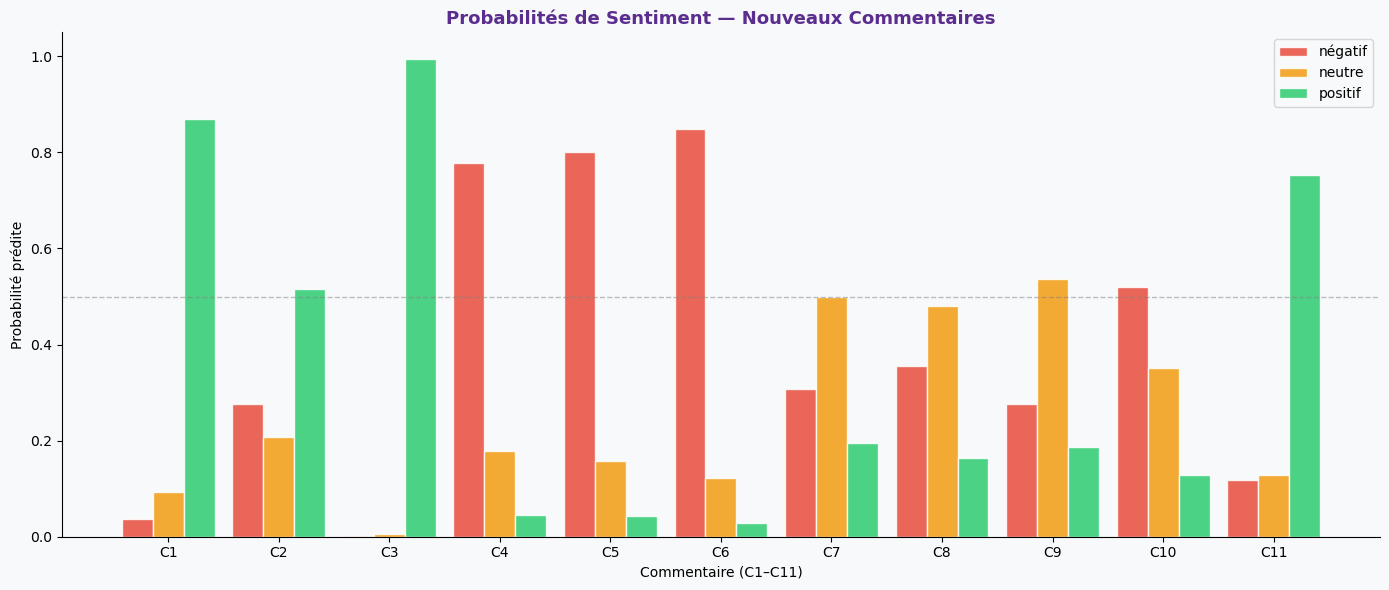


 Légende des commentaires :
  C01 : La Renault 5 E-Tech est une merveille ! Autonomie parfaite pour la ville, v...
  C02 : I absolutely love my new Renault Austral. Best car I have ever owned, smoot...
  C03 : Très satisfait de ma Dacia Spring. Parfaite pour les trajets urbains, écono...
  C04 : Ma Renault Mégane E-Tech tombe en panne pour la troisième fois. Le SAV est ...
  C05 : Terrible experience with the Zoe. Battery degradation after 1 year is unacc...
  C06 : Le GPS de ma Captur plante constamment. Interface catastrophique, je regret...
  C07 : La Renault Clio est une voiture correcte. Ni exceptionnelle ni mauvaise, da...
  C08 : The Renault Arkana is decent but nothing special. Adequate for daily commut...
  C09 : Véhicule honnête dans son ensemble. Quelques points à améliorer sur les fin...
  C10 : Bonne voiture mais le service après-vente laisse vraiment à désirer.
  C11 : Excellent rapport qualité-prix mais quelques problèmes de connectivité Blue...


In [21]:
# ── Visualisation des prédictions ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor(COLORS['bg'])

# Récupérer les probabilités pour chaque commentaire
texts_clean_ex = [preprocess_text(t) for t in nouveaux_commentaires]
seqs_ex        = tokenizer.texts_to_sequences(texts_clean_ex)
padded_ex      = pad_sequences(seqs_ex, maxlen=MAX_LEN, padding='post', truncating='post')
probas_ex      = cnn_model.predict(padded_ex, verbose=0)

x = np.arange(len(nouveaux_commentaires))
width = 0.28

for i, (label, color) in enumerate(zip(LABEL_NAMES,
        [COLORS['négatif'], COLORS['neutre'], COLORS['positif']])):
    ax.bar(x + i*width, probas_ex[:, i], width=width,
           label=label, color=color, alpha=0.85, edgecolor='white')

short_labels = [f'C{i+1}' for i in range(len(nouveaux_commentaires))]
ax.set_xticks(x + width)
ax.set_xticklabels(short_labels, fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Commentaire (C1–C11)')
ax.set_ylabel('Probabilité prédite')
ax.set_title('Probabilités de Sentiment — Nouveaux Commentaires',
             fontweight='bold', color=COLORS['purple'], fontsize=13)
ax.legend(fontsize=10)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.tight_layout()
plt.show()

# Légende
print('\n Légende des commentaires :')
for i, c in enumerate(nouveaux_commentaires, 1):
    print(f'  C{i:02d} : {c[:75]}...' if len(c) > 75 else f'  C{i:02d} : {c}')

---
## Section 9 — Conclusions et Pistes d'Amélioration

###  Bilan des résultats

Nous avons construit et comparé **3 approches** pour l'analyse de sentiment :

| Approche | Méthode | Avantages | Limites |
|----------|---------|-----------|--------|
| Baseline 1 | TF-IDF + Régression Logistique | Rapide, interprétable | Ignore l'ordre des mots |
| Baseline 2 | TF-IDF + SVM | Robuste, haute dim | Pas de probabilités |
| **Deep Learning** | **CNN + Embeddings** | Capte la sémantique, end-to-end | Plus de données requises |

###  Ce que le CNN apporte par rapport au TF-IDF

- **Représentations denses** : chaque mot est un vecteur de 64 dimensions (vs. vecteur creux en TF-IDF)
- **Contexte local** : les filtres Conv1D capturent des n-grammes appris automatiquement
- **Représentations apprises** : les embeddings s'adaptent à la tâche de sentiment
- **Passage à l'échelle** : efficace sur de grands volumes de données textuelles

###  Pistes d'amélioration

#### 1. Modèles pré-entraînés (state-of-the-art)
Utiliser des modèles de langage pré-entraînés comme :
- **CamemBERT** : BERT français (idéal pour notre dataset 60% FR)
- **XLM-RoBERTa** : multilingue (FR + EN en même temps)
- **Fine-tuning** sur notre corpus Renault

```python
# Exemple avec HuggingFace
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
model = TFAutoModelForSequenceClassification.from_pretrained('camembert-base', num_labels=3)
```

#### 2. Augmentation des données
- **Back-translation** : traduire FR→EN→FR pour diversifier les avis
- **Paraphrase** avec un modèle de génération
- **Mixup** textuel

#### 3. Architecture CNN plus riche
- **Multi-kernel CNN** : filtres de taille 2, 3, 4 en parallèle (comme TextCNN de Kim 2014)
- **CNN + BiLSTM** hybride
- **Attention mechanism** sur les sorties Conv

#### 4. Embeddings pré-entraînés
- Initialiser la couche Embedding avec **FastText (fr)** ou **GloVe**
- Puis fine-tuner sur nos données

#### 5. Déploiement
- Export du modèle en **TensorFlow SavedModel** ou **ONNX**
- Déploiement via **FastAPI** ou **Streamlit**
- Intégration dans un pipeline MLOps (MLflow, Vertex AI)

---

### Références

- Kim, Y. (2014). *Convolutional Neural Networks for Sentence Classification*. EMNLP.
- Devlin et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers*. NAACL.
- Martin et al. (2020). *CamemBERT: a Tasty French Language Model*. ACL.
- Liu et al. (2019). *RoBERTa: A Robustly Optimized BERT Pretraining Approach*.

In [22]:
# ── Résumé final ─────────────────────────────────────────────────────────────
print('='*60)
print('  RÉSUMÉ FINAL — PROJET ANALYSE DE SENTIMENT RENAULT')
print('='*60)
print(f'\n Dataset :')
print(f'   Avis analysés : {len(df):,}')
print(f'   Langues       : Français ({(df["language"]=="fr").sum():,}) + Anglais ({(df["language"]=="en").sum():,})')
print(f'   Période       : 2020–2024')
print(f'   Modèles       : {df["model"].nunique()} modèles Renault/Dacia/Alpine')
print()
print(f'Modèles entraînés :')
for m in ml_results:
    print(f'   {m:<32} → Acc={ml_results[m]["accuracy"]:.3f} | F1={ml_results[m]["f1_macro"]:.3f}')
print(f'   {"CNN (Conv1D + Embeddings)":<32} → Acc={test_acc:.3f} | F1={f1_test:.3f}  ← Best')
print()
print(f'  Architecture CNN :')
print(f'   Embedding({VOCAB_SIZE}, {EMBED_DIM}) → Conv1D(128,3) → MaxPool →')
print(f'   Conv1D(64,3) → GlobalMaxPool → Dense(128) → Softmax(3)')
print(f'   Paramètres : {cnn_model.count_params():,}')
print()
print('  Projet terminé avec succès!')
print('\n Points clés à retenir :')
print('   1. Le prétraitement NLP est crucial (stopwords, tokenisation)')
print('   2. Les baselines ML sont de bons points de départ')
print('   3. Le CNN capture la structure locale des phrases')
print('   4. Pour battre le CNN : essayer CamemBERT ou XLM-RoBERTa')

  RÉSUMÉ FINAL — PROJET ANALYSE DE SENTIMENT RENAULT

 Dataset :
   Avis analysés : 2,455
   Langues       : Français (1,497) + Anglais (958)
   Période       : 2020–2024
   Modèles       : 12 modèles Renault/Dacia/Alpine

Modèles entraînés :
   Régression Logistique            → Acc=1.000 | F1=1.000
   SVM Linéaire                     → Acc=1.000 | F1=1.000
   CNN (Conv1D + Embeddings)        → Acc=1.000 | F1=1.000  ← Best

  Architecture CNN :
   Embedding(10000, 64) → Conv1D(128,3) → MaxPool →
   Conv1D(64,3) → GlobalMaxPool → Dense(128) → Softmax(3)
   Paramètres : 698,051

  Projet terminé avec succès!

 Points clés à retenir :
   1. Le prétraitement NLP est crucial (stopwords, tokenisation)
   2. Les baselines ML sont de bons points de départ
   3. Le CNN capture la structure locale des phrases
   4. Pour battre le CNN : essayer CamemBERT ou XLM-RoBERTa
